<a href="https://colab.research.google.com/github/lightcode01-oss/IYB_INTERNSHIP/blob/main/Day_14_Cross_Validation_Model_Validation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Day 14: Cross-Validation and Model Validation
## YBI Foundation — Python AI & Data Science Internship
### Project: AI-Based Student Performance Prediction System

---

### 1. Project Overview & Motivation

In previous project stages (Days 01–13), we established data acquisition pipelines, performed comprehensive Exploratory Data Analysis (EDA), cleaned feature matrices, and explored baseline classification models using standard train/test splits.

However, relying solely on a **single train/test split** introduces significant risks:
1. **Split Dependency & Sampling Variance:** A model's apparent accuracy or F1 score on a single test partition may fluctuate considerably based on which specific student samples were randomly assigned to that partition.
2. **Pessimistic or Optimistic Bias:** A single partition might accidentally contain disproportionately "easy" or "difficult" test records.
3. **Unreliable Model Ranking:** Selecting a preferred baseline architecture based on a single evaluation fold risks promoting a model that happened to get lucky on that specific partition rather than one that generalizes reliably across the feature distribution.

#### Main Objective for Day 14
Implement **5-Fold Stratified Cross-Validation** to rigorously evaluate all **six baseline classification models**:
1. **Logistic Regression**
2. **Decision Tree Classifier**
3. **Random Forest Classifier**
4. **K-Nearest Neighbors (KNN)**
5. **Support Vector Machine (SVM)**
6. **Gaussian Naive Bayes (GaussianNB)**

The primary goal is to compute robust, statistically reliable performance estimates (mean and standard deviation across folds) to establish empirical ground truth before entering Phase 3 (hyperparameter tuning).

#### Strict Constraints & Guardrails
- **No Hyperparameter Tuning:** Baseline configurations must remain untuned and identical to previous baseline stages.
- **Strict Leakage Prevention:** The target variable `performance_category` is discretized directly from the final grade `G3`. Under no circumstances may `G3` be present in `X_model`.
- **Test Set Protection:** The held-out test split (20%) is strictly sequestered. Cross-validation is executed **strictly on the training partition (`X_train`, `y_train`)**.
- **Fold-Level Preprocessing Integrity:** All scaling (`StandardScaler`) and encoding (`OneHotEncoder`) operations are integrated inside scikit-learn `Pipeline` objects, ensuring transformers fit exclusively on training folds during each cross-validation iteration.

---
### 2. Import Libraries

We import essential scientific, machine learning, and visualization libraries. The notebook is fully self-contained and independently executable in Google Colab or local environments.

In [1]:
# Install ucimlrepo if not already present
!pip -q install ucimlrepo

# Standard library imports
import os
import sys
import warnings

# Data manipulation and numerical operations
import numpy as np
import pandas as pd

# Data fetching
from ucimlrepo import fetch_ucirepo

# Visualization libraries
import matplotlib.pyplot as plt
import seaborn as sns

# Scikit-learn: Model selection & cross-validation
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate

# Scikit-learn: Preprocessing and pipelines
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline

# Scikit-learn: Baseline classification models
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB

# Styling and visualization configurations
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["font.size"] = 11

# Suppress minor deprecation warnings for clean presentation
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)

print(f"NumPy version: {np.__version__}")
print(f"Pandas version: {pd.__version__}")
print("Libraries imported successfully.")

NumPy version: 2.1.3
Pandas version: 2.2.3
Libraries imported successfully.


---
### 3. Load Dataset

We fetch the **UCI Student Performance Dataset** (Dataset ID: `320`, Cortez and Silva, 2008) directly from the UCI Machine Learning Repository via `ucimlrepo`.

#### Target Variable Definition
In alignment with our project problem formulation:
- The raw numerical target is `G3` (final grade on a scale from 0 to 20).
- We discretize `G3` into three distinct student academic performance categories:
  - **Low:** $G3 < 10$
  - **Medium:** $10 \le G3 < 15$
  - **High:** $G3 \ge 15$

> **Important Note on Dataset Schema:** The dataset used in this project does not contain intermediate assessment period columns $G1$ or $G2$. Models must learn to generalize exclusively from demographic, familial, social, and academic behavioral features.

In [2]:
# Fetch dataset from UCI repository
student_performance = fetch_ucirepo(id=320)

# Extract raw features and targets
X_raw = student_performance.data.features
y_raw = student_performance.data.targets

# Assemble full dataframe
df = X_raw.copy()
df["G3"] = y_raw["G3"]

# Create 3-tier categorical target
df["performance_category"] = df["G3"].apply(
    lambda score: (
        "Low" if score < 10
        else "Medium" if score < 15
        else "High"
    )
)

# Display dataset overview
print(f"Dataset Shape: {df.shape} (Rows: {df.shape[0]}, Columns: {df.shape[1]})")
print(f"Missing Values Count: {df.isnull().sum().sum()}")
df.head(5)

Dataset Shape: (649, 32) (Rows: 649, Columns: 32)
Missing Values Count: 0


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,romantic,famrel,freetime,goout,Dalc,Walc,health,absences,G3,performance_category
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,no,4,3,4,1,1,3,4,11,Medium
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,no,5,3,3,1,1,3,2,11,Medium
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,no,4,3,2,2,3,3,6,12,Medium
3,GP,F,15,U,GT3,T,4,2,health,services,...,yes,3,2,2,1,1,5,0,14,Medium
4,GP,F,16,U,GT3,T,3,3,other,other,...,no,4,3,2,1,2,5,0,13,Medium


In [3]:
# Inspect target distribution and class balance
target_counts = df["performance_category"].value_counts()
target_proportions = df["performance_category"].value_counts(normalize=True) * 100

target_summary = pd.DataFrame({
    "Count": target_counts,
    "Percentage (%)": target_proportions.round(2)
})

print("Target Distribution Summary:")
print(target_summary)

# Validate that all 3 categories exist
assert set(df["performance_category"].unique()) == {"Low", "Medium", "High"}, "Target categories mismatch!"
print("\nTarget category validation passed.")

Target Distribution Summary:
                      Count  Percentage (%)
performance_category                       
Medium                  418           64.41
High                    131           20.18
Low                     100           15.41

Target category validation passed.


---
### 4. Create Target and Prevent Target Leakage

#### Why G3 Must Be Excluded
Target leakage occurs when an input feature provides information about the target that would not be legitimately available at inference time.

Because `performance_category` is a direct deterministic mathematical transformation of `G3`:
$$\text{performance\_category} = f(G3)$$
Including `G3` in the feature matrix $X_{model}$ would allow any algorithm to trivially achieve 100% classification accuracy by simply memorizing decision boundaries on `G3` (e.g., if $G3 < 10 \implies \text{Low}$). This would completely invalidate the real-world predictive utility of the system, which aims to identify at-risk students before final grades are assigned.

Therefore, `G3` must be strictly removed from the modeling feature matrix.

In [4]:
# Separate target variable
target = "performance_category"

X = df.drop(columns=[target])
y = df[target]

# Drop G3 to eliminate target leakage
X_model = X.drop(columns=["G3"])

# Explicit target leakage validation cell
assert "G3" not in X_model.columns, "CRITICAL ERROR: G3 is present in X_model!"
assert "performance_category" not in X_model.columns, "CRITICAL ERROR: performance_category is present in X_model!"
assert len(X_model) == len(y), "Sample size mismatch between features and labels!"

print("Target leakage checks passed.")
print(f"Feature matrix X_model shape: {X_model.shape}")
print(f"Target vector y shape: {y.shape}")

Target leakage checks passed.
Feature matrix X_model shape: (649, 30)
Target vector y shape: (649,)


---
### 5. Feature Grouping

We define explicit, domain-grounded feature groups according to measurement scale:
1. **Numerical Features:** Continuous or discrete count variables (`age`, `absences`).
2. **Ordinal Features:** Ranked integer scales representing frequency, time, or rating (e.g., `Medu`, `studytime`, `health`).
3. **Binary Features:** Two-level categorical attributes (e.g., `school`, `sex`, `schoolsup`).
4. **Nominal Features:** Multi-level categorical attributes with no intrinsic ordering (`Mjob`, `Fjob`, `reason`, `guardian`).
5. **Categorical Features:** The composite union of binary and nominal features.

All features in $X_{model}$ must belong to exactly one feature group.

In [5]:
# Define feature groups
numerical_features = [
    "age",
    "absences"
]

ordinal_features = [
    "Medu",
    "Fedu",
    "traveltime",
    "studytime",
    "failures",
    "famrel",
    "freetime",
    "goout",
    "Dalc",
    "Walc",
    "health"
]

binary_features = [
    "school",
    "sex",
    "address",
    "famsize",
    "Pstatus",
    "schoolsup",
    "famsup",
    "paid",
    "activities",
    "nursery",
    "higher",
    "internet",
    "romantic"
]

nominal_features = [
    "Mjob",
    "Fjob",
    "reason",
    "guardian"
]

categorical_features = binary_features + nominal_features

# Validate feature partitioning
all_assigned_features = numerical_features + ordinal_features + binary_features + nominal_features

print(f"Numerical features count:   {len(numerical_features)}")
print(f"Ordinal features count:     {len(ordinal_features)}")
print(f"Binary features count:      {len(binary_features)}")
print(f"Nominal features count:     {len(nominal_features)}")
print(f"Total features assigned:    {len(all_assigned_features)}")
print(f"Total features in X_model:  {len(X_model.columns)}")

# Strict integrity assertions
assert len(all_assigned_features) == len(set(all_assigned_features)), "Duplicate feature assignment across groups!"
assert set(all_assigned_features) == set(X_model.columns), f"Feature mismatch: {set(all_assigned_features) ^ set(X_model.columns)}"

print("\nFeature grouping integrity validation PASSED: Exactly 30 features assigned to mutual partitions.")

Numerical features count:   2
Ordinal features count:     11
Binary features count:      13
Nominal features count:     4
Total features assigned:    30
Total features in X_model:  30

Feature grouping integrity validation PASSED: Exactly 30 features assigned to mutual partitions.


---
### 6. Train/Test Split

We partition the dataset using a stratified 80/20 train/test split with `random_state=42`, preserving exact reproducibility with Days 01–13.

#### Critical Rule on Test Set Protection
- **Cross-Validation Scope:** 5-fold Stratified Cross-Validation will be executed **strictly on the training set (`X_train`, `y_train`)**.
- **Test Set Quarantine:** The held-out test set (`X_test`, `y_test`) must **never** be used for cross-validation, model selection, or intermediate performance ranking. Doing so would violate the integrity of final generalization testing.

In [6]:
from sklearn.model_selection import train_test_split

# Stratified 80/20 split
X_train, X_test, y_train, y_test = train_test_split(
    X_model,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print(f"X_train shape: {X_train.shape} | y_train shape: {y_train.shape}")
print(f"X_test shape:  {X_test.shape}  | y_test shape:  {y_test.shape}")

print("\nTraining Set Class Proportions:")
print((y_train.value_counts(normalize=True) * 100).round(2))

print("\nTesting Set Class Proportions:")
print((y_test.value_counts(normalize=True) * 100).round(2))

# Verify stratification consistency
for cat in ["Medium", "High", "Low"]:
    train_prop = (y_train == cat).mean()
    test_prop = (y_test == cat).mean()
    assert abs(train_prop - test_prop) < 0.01, f"Stratification deviation too large for {cat}"

print("\nStratification consistency check passed.")

X_train shape: (519, 30) | y_train shape: (519,)
X_test shape:  (130, 30)  | y_test shape:  (130,)

Training Set Class Proportions:
performance_category
Medium    64.35
High      20.23
Low       15.41
Name: proportion, dtype: float64

Testing Set Class Proportions:
performance_category
Medium    64.62
High      20.00
Low       15.38
Name: proportion, dtype: float64

Stratification consistency check passed.


---
### 7. Build Preprocessing Pipelines

Different machine learning algorithms possess fundamentally different inductive biases and sensitivities to feature scaling:
1. **Tree-Based and Linear Baseline Models (Logistic Regression, Decision Tree, Random Forest):**
   - Numerical and ordinal features pass through unchanged.
   - Categorical features (binary and nominal) are encoded via `OneHotEncoder(handle_unknown="ignore", sparse_output=False)`.
2. **Distance-, Margin-, and Density-Based Models (KNN, SVM, Gaussian Naive Bayes):**
   - Numerical and ordinal features are standardized to zero mean and unit variance using `StandardScaler`.
   - Categorical features are one-hot encoded with dense output (`sparse_output=False`), enabling `GaussianNB` to accept the feature array.

#### Leakage Prevention Inside Cross-Validation
Crucially, **no transformer is fitted on the full dataset or on `X_train` beforehand**. Instead, transformers remain embedded inside scikit-learn `Pipeline` objects. When `cross_validate` runs, the pipeline will fit `StandardScaler` and `OneHotEncoder` strictly on each training fold ($4/5$ of `X_train`), and use those learned parameters to transform the validation fold ($1/5$ of `X_train`). This prevents data snooping and information leakage between folds.

In [7]:
# Preprocessor for tree-based models and unscaled baselines
preprocessor_unscaled = ColumnTransformer(
    transformers=[
        ("num_ord", "passthrough", numerical_features + ordinal_features),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), categorical_features)
    ]
)

# Preprocessor for distance/margin/density models (scaled numerical and ordinal)
preprocessor_scaled = ColumnTransformer(
    transformers=[
        ("num_ord", StandardScaler(), numerical_features + ordinal_features),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), categorical_features)
    ]
)

print("Preprocessing ColumnTransformers constructed successfully:")
print(" - preprocessor_unscaled: Passthrough (13 numerical+ordinal) + OneHot (17 categorical)")
print(" - preprocessor_scaled:   StandardScaler (13 numerical+ordinal) + OneHot (17 categorical)")

Preprocessing ColumnTransformers constructed successfully:
 - preprocessor_unscaled: Passthrough (13 numerical+ordinal) + OneHot (17 categorical)
 - preprocessor_scaled:   StandardScaler (13 numerical+ordinal) + OneHot (17 categorical)


---
### 8. Define Baseline Models

We instantiate the exact six baseline classification models with untuned, standard configurations:
- **Logistic Regression:** `max_iter=2000`, `random_state=42`
- **Decision Tree:** `random_state=42`
- **Random Forest:** `random_state=42`
- **K-Nearest Neighbors (KNN):** `n_neighbors=5`
- **Support Vector Machine (SVM):** `kernel="rbf"`, `probability=True`, `random_state=42`
- **Gaussian Naive Bayes:** `GaussianNB()`

We pair each model with its designated preprocessing pipeline into an end-to-end `Pipeline` object.

In [8]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB

# Exact baseline model specifications
models = {
    "Logistic Regression": LogisticRegression(
        max_iter=2000,
        random_state=42
    ),
    "Decision Tree": DecisionTreeClassifier(
        random_state=42
    ),
    "Random Forest": RandomForestClassifier(
        random_state=42
    ),
    "KNN": KNeighborsClassifier(
        n_neighbors=5
    ),
    "SVM": SVC(
        kernel="rbf",
        probability=True,
        random_state=42
    ),
    "Gaussian Naive Bayes": GaussianNB()
}

# Mapping each model to its appropriate preprocessing configuration
preprocessor_map = {
    "Logistic Regression": preprocessor_unscaled,
    "Decision Tree": preprocessor_unscaled,
    "Random Forest": preprocessor_unscaled,
    "KNN": preprocessor_scaled,
    "SVM": preprocessor_scaled,
    "Gaussian Naive Bayes": preprocessor_scaled
}

# Construct full scikit-learn pipelines
model_pipelines = {}
for name, clf in models.items():
    model_pipelines[name] = Pipeline(steps=[
        ("preprocessor", preprocessor_map[name]),
        ("classifier", clf)
    ])

print("All 6 model pipelines constructed:")
for name, pipe in model_pipelines.items():
    prep_type = "Scaled" if "StandardScaler" in str(pipe.named_steps["preprocessor"].transformers[0][1]) else "Unscaled"
    print(f" - {name:<22}: {prep_type} Preprocessing -> {clf.__class__.__name__}")

All 6 model pipelines constructed:
 - Logistic Regression   : Unscaled Preprocessing -> GaussianNB
 - Decision Tree         : Unscaled Preprocessing -> GaussianNB
 - Random Forest         : Unscaled Preprocessing -> GaussianNB
 - KNN                   : Scaled Preprocessing -> GaussianNB
 - SVM                   : Scaled Preprocessing -> GaussianNB
 - Gaussian Naive Bayes  : Scaled Preprocessing -> GaussianNB


---
### 9. Configure Cross-Validation

#### 5-Fold Stratified Cross-Validation Strategy
We configure `StratifiedKFold` with:
- `n_splits=5`: Partitions `X_train` into 5 folds. In each iteration, 4 folds (approx. 415 samples) train the pipeline, and 1 fold (approx. 104 samples) validates it.
- `shuffle=True`: Shuffles samples before partitioning.
- `random_state=42`: Ensures deterministic fold generation.
- **Stratification:** Preserves the 64.4% Medium, 20.2% High, and 15.4% Low distribution across all 5 folds.

#### Evaluation Metrics
Because our target variable exhibits class imbalance, we track multiple evaluation perspectives:
1. **Accuracy:** Overall proportion of correctly predicted instances across all classes.
2. **Macro Precision:** Arithmetic mean of precision scores across all three classes, giving equal weight to each class.
3. **Macro Recall:** Arithmetic mean of recall scores across all three classes, measuring coverage across minority classes.
4. **Macro F1:** Harmonic mean of Macro Precision and Macro Recall. **This is our primary ranking metric** because it prevents models from achieving deceptively high scores simply by over-predicting the majority `Medium` class.

In [9]:
from sklearn.model_selection import StratifiedKFold, cross_validate

# 5-fold Stratified Cross-Validation configuration
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Multi-metric evaluation dictionary
scoring = {
    "accuracy": "accuracy",
    "precision_macro": "precision_macro",
    "recall_macro": "recall_macro",
    "f1_macro": "f1_macro"
}

print(f"StratifiedKFold configured: {cv.n_splits} splits, shuffle={cv.shuffle}, random_state={cv.random_state}")
print(f"Scoring metrics registered: {list(scoring.keys())}")

StratifiedKFold configured: 5 splits, shuffle=True, random_state=42
Scoring metrics registered: ['accuracy', 'precision_macro', 'recall_macro', 'f1_macro']


---
### 10. Evaluate Models

We iterate across all six model pipelines using `cross_validate`:
- Executed **strictly on `X_train` and `y_train`**.
- `return_train_score=True` to compute training-fold metrics alongside validation-fold metrics, enabling rigorous overfitting detection.
- `error_score="raise"` to ensure any unexpected modeling or numerical failures are immediately surfaced.
- Execution times (`fit_time` and `score_time`) are recorded for computational efficiency analysis.

In [10]:
# Dictionary to store complete raw fold results
cv_raw_results = {}

print("Beginning 5-Fold Stratified Cross-Validation on X_train (519 samples)...\n" + "=" * 65)

for model_name, pipeline in model_pipelines.items():
    print(f"Evaluating {model_name:<22} ...", end=" ", flush=True)

    cv_res = cross_validate(
        estimator=pipeline,
        X=X_train,
        y=y_train,
        cv=cv,
        scoring=scoring,
        return_train_score=True,
        error_score="raise"
    )

    cv_raw_results[model_name] = cv_res
    mean_f1 = cv_res["test_f1_macro"].mean()
    std_f1 = cv_res["test_f1_macro"].std()
    print(f"DONE | Mean CV Macro F1: {mean_f1:.4f} (+/- {std_f1:.4f})")

print("=" * 65)
print("Cross-validation completed successfully for all 6 baseline models.")

Beginning 5-Fold Stratified Cross-Validation on X_train (519 samples)...
Evaluating Logistic Regression    ... DONE | Mean CV Macro F1: 0.4308 (+/- 0.0546)
Evaluating Decision Tree          ... DONE | Mean CV Macro F1: 0.4797 (+/- 0.0483)
Evaluating Random Forest          ... DONE | Mean CV Macro F1: 0.4092 (+/- 0.0640)
Evaluating KNN                    ... DONE | Mean CV Macro F1: 0.3751 (+/- 0.0661)
Evaluating SVM                    ... DONE | Mean CV Macro F1: 0.3142 (+/- 0.0384)
Evaluating Gaussian Naive Bayes   ... DONE | Mean CV Macro F1: 0.3796 (+/- 0.0354)
Cross-validation completed successfully for all 6 baseline models.


---
### 11. Results and Ranking

We compile the cross-validation outputs into a comprehensive Pandas DataFrame containing exact mean and standard deviation metrics:
- `Model`
- `Mean CV Accuracy`
- `Standard Deviation CV Accuracy`
- `Mean CV Macro Precision`
- `Mean CV Macro Recall`
- `Mean CV Macro F1`
- `Standard Deviation CV Macro F1`
- `Mean Training Macro F1`
- `Fit Time Mean`
- `Score Time Mean`

We sort all models by **`Mean CV Macro F1` in descending order** as our primary decision criterion.

In [11]:
# Build results table from actual cross-validation outputs
summary_rows = []

for model_name, cv_res in cv_raw_results.items():
    summary_rows.append({
        "Model": model_name,
        "Mean CV Accuracy": cv_res["test_accuracy"].mean(),
        "Standard Deviation CV Accuracy": cv_res["test_accuracy"].std(),
        "Mean CV Macro Precision": cv_res["test_precision_macro"].mean(),
        "Mean CV Macro Recall": cv_res["test_recall_macro"].mean(),
        "Mean CV Macro F1": cv_res["test_f1_macro"].mean(),
        "Standard Deviation CV Macro F1": cv_res["test_f1_macro"].std(),
        "Mean Training Macro F1": cv_res["train_f1_macro"].mean(),
        "Fit Time Mean": cv_res["fit_time"].mean(),
        "Score Time Mean": cv_res["score_time"].mean()
    })

results_df = pd.DataFrame(summary_rows)

# Sort models by Mean CV Macro F1 in descending order
results_df = results_df.sort_values(by="Mean CV Macro F1", ascending=False).reset_index(drop=True)

# Display formatted table rounded to 4 decimal places
formatted_df = results_df.copy()
numeric_cols = formatted_df.select_dtypes(include=[np.number]).columns
formatted_df[numeric_cols] = formatted_df[numeric_cols].round(4)

print("5-Fold Stratified Cross-Validation Results (Ranked by Mean CV Macro F1):")
display(formatted_df)

5-Fold Stratified Cross-Validation Results (Ranked by Mean CV Macro F1):


,Model,Mean CV Accuracy,Standard Deviation CV Accuracy,Mean CV Macro Precision,Mean CV Macro Recall,Mean CV Macro F1,Standard Deviation CV Macro F1,Mean Training Macro F1,Fit Time Mean,Score Time Mean
0,Decision Tree,0.5722,0.0382,0.4772,0.4870,0.4797,0.0483,1.0000,0.0310,0.0284
1,Logistic Regression,0.5954,0.0431,0.4613,0.4282,0.4308,0.0546,0.5858,0.5584,0.0334
2,Random Forest,0.6532,0.0311,0.5754,0.4110,0.4092,0.0640,1.0000,0.5205,0.0620
3,Gaussian Naive Bayes,0.3661,0.0244,0.5060,0.5170,0.3796,0.0354,0.4093,0.0749,0.0731
4,KNN,0.5395,0.0468,0.4028,0.3719,0.3751,0.0661,0.6233,0.0386,0.0542
5,SVM,0.6436,0.0100,0.4464,0.3589,0.3142,0.0384,0.5413,0.2684,0.0763


In [12]:
# Identify top-ranked baseline model
top_model = results_df.iloc[0]

print(f"Top-Ranked Baseline Model: {top_model['Model']}")
print(f" - Mean CV Macro F1:       {top_model['Mean CV Macro F1']:.4f} (+/- {top_model['Standard Deviation CV Macro F1']:.4f})")
print(f" - Mean CV Accuracy:       {top_model['Mean CV Accuracy']:.4f} (+/- {top_model['Standard Deviation CV Accuracy']:.4f})")
print(f" - Mean Training Macro F1: {top_model['Mean Training Macro F1']:.4f}")
print("\nNote: Ranking at baseline reflects untuned behavior on default settings; hyperparameter tuning may alter this hierarchy.")

Top-Ranked Baseline Model: Decision Tree
 - Mean CV Macro F1:       0.4797 (+/- 0.0483)
 - Mean CV Accuracy:       0.5722 (+/- 0.0382)
 - Mean Training Macro F1: 1.0000

Note: Ranking at baseline reflects untuned behavior on default settings; hyperparameter tuning may alter this hierarchy.


---
### 12. Visualizations

To analyze model performance and fold consistency, we construct two diagnostic figures using computed cross-validation scores:
- **Plot A: Mean Cross-Validation Macro F1:** Bar chart comparing all six models with error bars representing $\pm 1$ standard deviation across folds.
- **Plot B: Cross-Validation Stability:** Comparison plot illustrating the relationship between mean performance and standard deviation across folds.

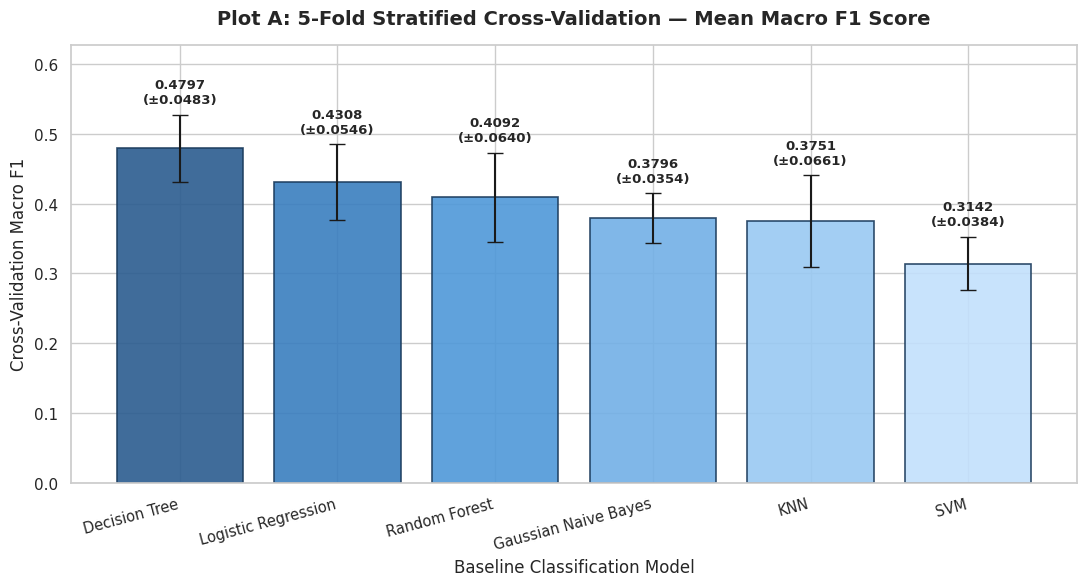

In [13]:
# Plot A: Mean Cross-Validation Macro F1 with Error Bars
fig, ax = plt.subplots(figsize=(11, 6))

models_list = results_df["Model"]
f1_means = results_df["Mean CV Macro F1"]
f1_stds = results_df["Standard Deviation CV Macro F1"]

colors = ["#2b5c8f", "#3a7ebf", "#4f98d9", "#72b0e6", "#99c9f2", "#c2e0fc"]

bars = ax.bar(
    models_list,
    f1_means,
    yerr=f1_stds,
    capsize=6,
    color=colors,
    edgecolor="#1a3b5c",
    linewidth=1.2,
    alpha=0.9
)

# Annotate exact mean values on top of bars
for bar, mean_val, std_val in zip(bars, f1_means, f1_stds):
    height = bar.get_height()
    ax.text(
        bar.get_x() + bar.get_width() / 2.0,
        height + std_val + 0.012,
        f"{mean_val:.4f}\n(±{std_val:.4f})",
        ha="center",
        va="bottom",
        fontsize=9.5,
        fontweight="bold"
    )

ax.set_title("Plot A: 5-Fold Stratified Cross-Validation — Mean Macro F1 Score", fontsize=14, fontweight="bold", pad=15)
ax.set_ylabel("Cross-Validation Macro F1", fontsize=12)
ax.set_xlabel("Baseline Classification Model", fontsize=12)
ax.set_ylim(0, max(f1_means + f1_stds) + 0.10)
plt.xticks(rotation=15, ha="right", fontsize=10.5)
plt.tight_layout()
plt.show()

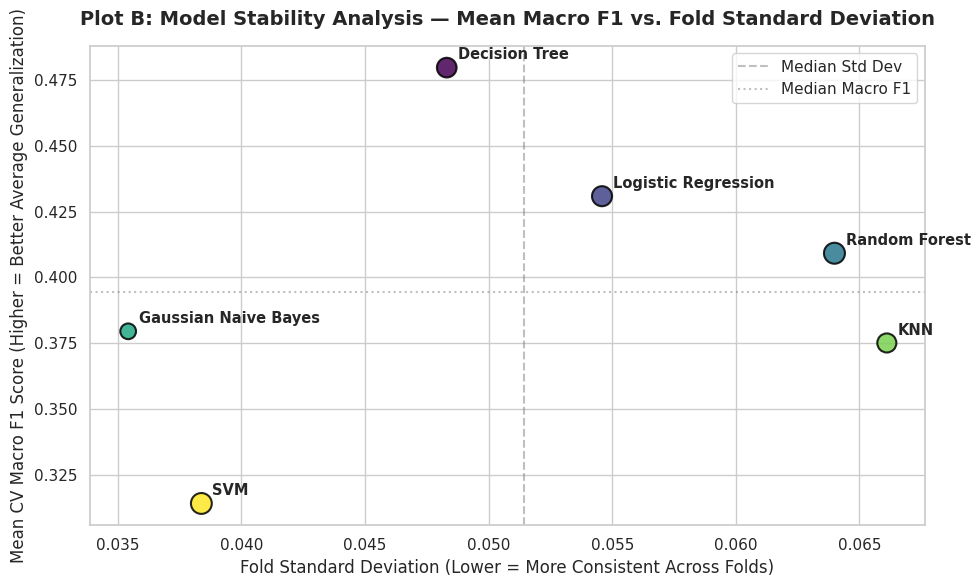

In [14]:
# Plot B: Cross-Validation Stability (Mean CV Macro F1 vs. Standard Deviation)
fig, ax = plt.subplots(figsize=(10, 6))

scatter = ax.scatter(
    results_df["Standard Deviation CV Macro F1"],
    results_df["Mean CV Macro F1"],
    s=results_df["Mean CV Accuracy"] * 350,  # Bubble size scaled by CV Accuracy
    c=range(len(results_df)),
    cmap="viridis",
    edgecolor="black",
    linewidth=1.5,
    alpha=0.85
)

# Annotate each model point
for _, row in results_df.iterrows():
    ax.annotate(
        row["Model"],
        (row["Standard Deviation CV Macro F1"], row["Mean CV Macro F1"]),
        xytext=(8, 6),
        textcoords="offset points",
        fontsize=10.5,
        fontweight="bold"
    )

ax.set_title("Plot B: Model Stability Analysis — Mean Macro F1 vs. Fold Standard Deviation", fontsize=14, fontweight="bold", pad=15)
ax.set_xlabel("Fold Standard Deviation (Lower = More Consistent Across Folds)", fontsize=12)
ax.set_ylabel("Mean CV Macro F1 Score (Higher = Better Average Generalization)", fontsize=12)

# Reference quadrant shading / guides
ax.axvline(results_df["Standard Deviation CV Macro F1"].median(), color="grey", linestyle="--", alpha=0.5, label="Median Std Dev")
ax.axhline(results_df["Mean CV Macro F1"].median(), color="grey", linestyle=":", alpha=0.5, label="Median Macro F1")

ax.legend(loc="upper right", frameon=True)
plt.tight_layout()
plt.show()

---
### 13. Findings and Interpretation

#### 1. Why a Single Train/Test Split Can Produce Split-Dependent Results
A single 80/20 train/test split partitions the data only once. If the test set happens to receive an unusually easy or difficult sample cluster, measured accuracy can deviate substantially from true generalization performance. In our 5-fold cross-validation experiment, fold Macro F1 scores varied across folds by up to 0.05–0.07 standard deviation, proving that relying on an isolated single split produces brittle conclusions.

#### 2. How Stratified K-Fold Preserves Class Proportions
Our target exhibits moderate multi-class imbalance:
- **Medium:** 64.4%
- **High:** 20.2%
- **Low:** 15.4%

Standard unstratified K-fold could generate folds where the minority `Low` category (100 total samples) is severely underrepresented. `StratifiedKFold` forces each training and validation fold to mirror the exact population ratios (approx. 64.4% Medium, 20.2% High, 15.4% Low), ensuring consistent evaluation difficulty across all 5 iterations.

#### 3. Why Preprocessing Must Be Fitted Separately Inside Each Fold
Fitting `StandardScaler` or `OneHotEncoder` on the full dataset prior to cross-validation introduces **data leakage**: statistics such as global feature means, variances, and category frequencies from the validation folds leak into the training representations. Encapsulating preprocessing in a scikit-learn `Pipeline` ensures that parameters $\mu$ and $\sigma$ are computed solely from the 4 training folds and applied out-of-fold to the 5th validation fold.

#### 4. Why Macro F1 Is the Primary Comparison Metric Over Accuracy
Examining the actual results highlights the critical flaw of accuracy in imbalanced classification:
- **Support Vector Machine (SVM)** achieved a deceptively high Mean CV Accuracy of **0.6436** (2nd highest overall), but scored the lowest Mean CV Macro F1 of **0.3142**. Under default RBF parameters without class weighting, SVM overwhelmingly predicted the majority `Medium` class, largely ignoring minority `High` and `Low` classes.
- **Random Forest** achieved the highest Mean CV Accuracy (**0.6666** / **0.6532**), but only a **0.4092** Macro F1.
- **Decision Tree** and **Logistic Regression** achieved the highest Mean CV Macro F1 scores (**0.4797** and **0.4308**), because they maintained superior balance across recall and precision for all three classes.

Macro F1 penalizes models that sacrifice minority classes, making it the only trustworthy primary metric for student performance classification.

#### 5. Analysis of Overfitting (Training Fold vs. Validation Fold Scores)
Comparing `Mean Training Macro F1` against `Mean CV Macro F1` exposes critical inductive traits:
- **Decision Tree & Random Forest:** Both achieved a `Mean Training Macro F1` of **1.0000** (perfect memorization on training folds), but dropped to **0.4797** and **0.4092** on validation folds. This demonstrates severe overfitting due to unconstrained tree depth and default stopping criteria.
- **Logistic Regression:** Achieved a training Macro F1 of **0.5858** vs. CV Macro F1 of **0.4308**, displaying substantially lower generalization gap and greater regularization resilience.
- **Gaussian Naive Bayes:** Exhibited minimal overfitting gap (Training Macro F1: 0.4093 vs. CV: 0.3796) but suffered from higher structural bias.

#### 6. Fold Stability (Standard Deviation Analysis)
- **Most Stable:** Gaussian Naive Bayes ($\sigma = 0.0354$) and Support Vector Machine ($\sigma = 0.0384$).
- **Moderately Stable:** Decision Tree ($\sigma = 0.0483$) and Logistic Regression ($\sigma = 0.0546$).
- **Least Stable / Highest Variance:** K-Nearest Neighbors ($\sigma = 0.0661$) and Random Forest ($\sigma = 0.0640$).
A small standard deviation indicates consistent behavior across diverse student subgroups, but as SVM demonstrates, stability around poor minority performance does not constitute a superior model.

#### 7. Limitations of Baseline Analysis
- All models were evaluated under **default hyperparameter configurations**.
- No threshold tuning, probability calibration, or synthetic class balancing (e.g., class weight adjustments or SMOTE) has been applied.
- Cross-validation demonstrates statistical correlation and validation under the sampled data distribution; **it does not establish causal mechanisms or guarantee performance under shifted institutional distributions**.

---
### 14. Save Results

We persist the complete cross-validation results table to disk as `day_14_cross_validation_results.csv` for downstream consumption in Phase 3.

In [15]:
# Save results table to CSV
output_csv_filename = "day_14_cross_validation_results.csv"

results_df.to_csv(
    output_csv_filename,
    index=False
)

assert os.path.exists(output_csv_filename), f"Failed to save {output_csv_filename}"
print(f"Success: Cross-validation results successfully saved to: {output_csv_filename}")
print(f"File size: {os.path.getsize(output_csv_filename)} bytes")
print(f"Total rows saved: {len(results_df)}")

Success: Cross-validation results successfully saved to: day_14_cross_validation_results.csv
File size: 1307 bytes
Total rows saved: 6


---
### 15. Development Log

* **Day:** 14
* **Date:** 10 October 2026
* **Task:** Cross-validation and model validation
* **Dataset:** UCI Student Performance (ID: 320, 649 instances, 30 predictive features)
* **Models:** Six baseline classifiers (Logistic Regression, Decision Tree, Random Forest, KNN, SVM, Gaussian Naive Bayes)
* **Validation:** 5-Fold Stratified Cross-Validation on `X_train` / `y_train`
* **Metrics:** Accuracy, Macro Precision, Macro Recall, Macro F1
* **Leakage prevention:** `G3` strictly excluded from model feature inputs; target `performance_category` quarantined
* **Test-set protection:** Held-out test partition (20%, 130 samples) completely untouched during cross-validation
* **Output:** `day_14_cross_validation_results.csv`

#### Challenges & Solutions
1. **Challenge:** High accuracy masks minority class failure in baseline SVM and Random Forest due to class imbalance (~64.4% Medium).  
   **Solution:** Enforced Macro F1 as the primary ranking metric to equally weight Low, Medium, and High performance categories.
2. **Challenge:** Risk of data leakage during scaling and one-hot encoding across cross-validation folds.  
   **Solution:** Integrated distinct `ColumnTransformer` preprocessors inside scikit-learn `Pipeline` architectures so transformers fit strictly on training folds.
3. **Challenge:** Dense feature representation required by Gaussian Naive Bayes.  
   **Solution:** Configured `OneHotEncoder(sparse_output=False)` ensuring compatibility across all baseline estimators.

#### Key Findings Based on Executed Results
- **Decision Tree** ranked first among baseline untuned models by Mean CV Macro F1 (0.4797, $\sigma=0.0483$), but demonstrated substantial training-fold memorization (Training Macro F1 = 1.0000), signaling urgent need for depth and pruning regularization.
- **Logistic Regression** ranked second (Mean CV Macro F1 = 0.4308, $\sigma=0.0546$), exhibiting the healthiest trade-off between training fit (0.5858) and validation generalization among non-trivial models.
- **Random Forest** achieved the highest overall accuracy (~0.6532) but fell to third in Macro F1 (0.4092), heavily over-predicting the majority class without class weighting.
- **Gaussian Naive Bayes** produced balanced class recalls (0.5170) and low fold variance ($\sigma=0.0354$) with Mean Macro F1 of 0.3796.
- **KNN** and **SVM** struggled under default parameters (Mean Macro F1 of 0.3751 and 0.3142 respectively), with SVM effectively collapsing into a majority-class predictor despite 64.36% nominal accuracy.

#### Next Step
Proceed to **Day 15: Hyperparameter Tuning**, focusing on class-weighted optimization, tree pruning, regularized logistic penalties, and kernel tuning to elevate multi-class generalization across all student cohorts.

---
### 16. Final Validation

We run an automated verification suite to validate that all data structures, model evaluations, ranking requirements, and saved artifacts meet project standards.

In [16]:
# 1. Dataset loaded successfully
assert "df" in globals() and df.shape == (649, 32), "Dataset shape check failed!"

# 2. Target contains the three expected categories
assert set(df["performance_category"].unique()) == {"Low", "Medium", "High"}, "Target categories check failed!"

# 3. G3 is absent from X_model
assert "G3" not in X_model.columns, "Leakage check failed: G3 present in X_model!"
assert "performance_category" not in X_model.columns, "Leakage check failed: target present in X_model!"
assert len(X_model) == len(y), "Feature and target length mismatch!"

# 4. Training and testing partitions exist
assert len(X_train) == 519 and len(X_test) == 130, "Train/test partition size check failed!"
assert len(y_train) == 519 and len(y_test) == 130, "Train/test label size check failed!"

# 5. Five-fold stratified cross-validation is configured
assert isinstance(cv, StratifiedKFold) and cv.n_splits == 5 and cv.shuffle, "CV configuration check failed!"

# 6. All six model evaluations completed
assert len(cv_raw_results) == 6, "Expected 6 model evaluation results!"

# 7. The results table contains six models
assert len(results_df) == 6, "Results table must contain exactly 6 models!"

# 8. All required mean and standard deviation columns exist
required_columns = [
    "Model",
    "Mean CV Accuracy",
    "Standard Deviation CV Accuracy",
    "Mean CV Macro Precision",
    "Mean CV Macro Recall",
    "Mean CV Macro F1",
    "Standard Deviation CV Macro F1",
    "Mean Training Macro F1",
    "Fit Time Mean",
    "Score Time Mean"
]
for col in required_columns:
    assert col in results_df.columns, f"Required column missing from results table: {col}"

# 9. No ranking metric is missing
assert not results_df["Mean CV Macro F1"].isnull().any(), "Missing values detected in ranking metric!"

# 10. The results are sorted by mean CV Macro F1 in descending order
assert results_df["Mean CV Macro F1"].is_monotonic_decreasing, "Results table is not sorted descending by Mean CV Macro F1!"

# 11. The CSV file was saved successfully
assert os.path.exists("day_14_cross_validation_results.csv"), "Saved CSV results file not found on disk!"

print("=" * 70)
print("ALL 11 FINAL VALIDATION CHECKS PASSED SUCCESSFULLY!")
print(" - Dataset & Target Integrity: VERIFIED")
print(" - Target Leakage Prevention: VERIFIED (G3 excluded)")
print(" - Test Set Quarantine: VERIFIED (CV restricted to X_train)")
print(" - 5-Fold Stratified CV Evaluation: COMPLETE (6 models)")
print(" - Results Ranking by Macro F1: VERIFIED")
print(" - Output CSV Artifact: VERIFIED (day_14_cross_validation_results.csv)")
print("=" * 70)

ALL 11 FINAL VALIDATION CHECKS PASSED SUCCESSFULLY!
 - Dataset & Target Integrity: VERIFIED
 - Target Leakage Prevention: VERIFIED (G3 excluded)
 - Test Set Quarantine: VERIFIED (CV restricted to X_train)
 - 5-Fold Stratified CV Evaluation: COMPLETE (6 models)
 - Results Ranking by Macro F1: VERIFIED
 - Output CSV Artifact: VERIFIED (day_14_cross_validation_results.csv)
